# 01 — Exploratory data analysis

This notebook inspects the cleaned UCI Default of Credit Card Clients data. Run `uv run credit-risk all` from the repository root first. The analysis is descriptive; category gaps are not causal effects.

In [1]:
%matplotlib inline
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'processed' / 'credit_default.csv'
if not DATA_PATH.exists():
    raise FileNotFoundError('Run `uv run credit-risk all` from the repository root first.')
data = pd.read_csv(DATA_PATH)
data.shape

(30000, 25)

In [2]:
summary = pd.DataFrame({
    'dtype': data.dtypes.astype(str),
    'missing': data.isna().sum(),
    'unique': data.nunique(),
})
summary

,dtype,missing,unique
ID,int64,0,30000
LIMIT_BAL,int64,0,81
SEX,int64,0,2
EDUCATION,int64,0,4
MARRIAGE,int64,0,3
AGE,int64,0,56
PAY_SEPT,int64,0,11
PAY_AUG,int64,0,11
PAY_JUL,int64,0,11
PAY_JUN,int64,0,11


In [3]:
target_summary = data['DEFAULT'].value_counts().rename(index={0: 'No default', 1: 'Default'}).to_frame('customers')
target_summary['share'] = target_summary['customers'] / len(data)
target_summary

,customers,share
DEFAULT,,
No default,23364,0.7788
Default,6636,0.2212


In [4]:
september_risk = (data.groupby('PAY_SEPT', as_index=False)
                  .agg(customers=('ID', 'size'), defaults=('DEFAULT', 'sum'), default_rate=('DEFAULT', 'mean')))
september_risk['default_rate_pct'] = 100 * september_risk['default_rate']
september_risk

,PAY_SEPT,customers,defaults,default_rate,default_rate_pct
0,-2,2759,365,0.132294,13.229431
1,-1,5686,954,0.167781,16.778051
2,0,14737,1888,0.128113,12.811291
3,1,3688,1252,0.339479,33.947939
4,2,2667,1844,0.691414,69.141357
5,3,322,244,0.757764,75.776398
6,4,76,52,0.684211,68.421053
7,5,26,13,0.500000,50.000000
8,6,11,6,0.545455,54.545455
9,7,9,7,0.777778,77.777778


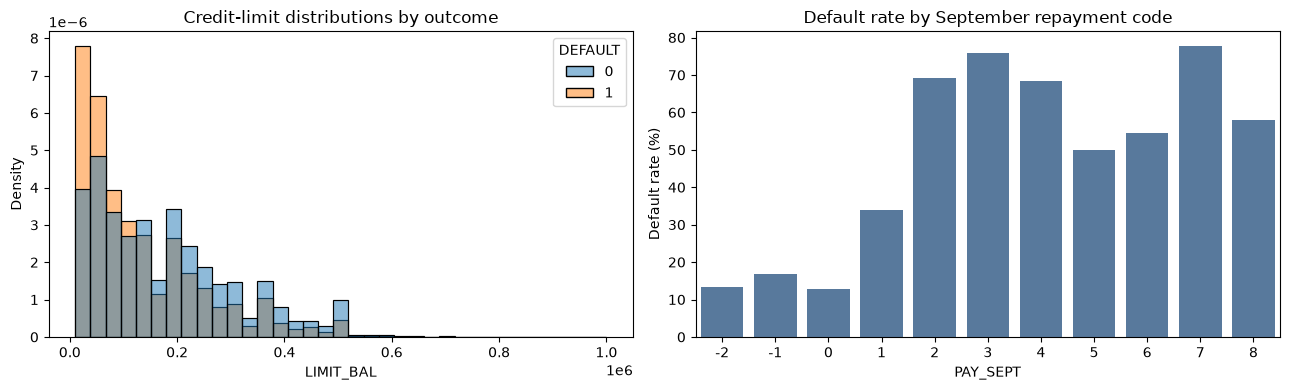

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=data, x='LIMIT_BAL', hue='DEFAULT', bins=35, stat='density', common_norm=False, ax=axes[0])
sns.barplot(data=september_risk, x='PAY_SEPT', y='default_rate_pct', color='#4C78A8', ax=axes[1])
axes[0].set_title('Credit-limit distributions by outcome')
axes[1].set_title('Default rate by September repayment code')
axes[1].set_ylabel('Default rate (%)')
plt.tight_layout();

## Interpretation guardrails

Repayment status is strongly associated with the recorded outcome, but this is not a causal analysis. Rare payment codes have unstable rates. The dataset includes only existing Taiwanese card customers in 2005 and cannot establish performance on new applicants, other products, regions, or time periods.